# Module 4: Unsupervised Learning — K-Means Clustering
## Comprehensive Customer Segmentation Analysis
**Course:** Data Science & Machine Learning (DSML)  
**Author:** Gagan Gautam  
**Dataset:** `customer_segmentation.csv` (Annual Income vs. Spending Score)

---

### Objectives of this Notebook
1. **Theoretical Foundations:** Understand the mathematical intuition behind Unsupervised Learning, Lloyd's Algorithm, Euclidean distance, and K-Means++ initialization.
2. **Exploratory Data Analysis (EDA):** Inspect distributions, summary statistics, and bivariate patterns of income and spending.
3. **From-Scratch Implementation:** Build a complete `KMeansScratch` class in pure NumPy to master the algorithmic mechanics.
4. **Optimal Cluster Selection:** Evaluate $K$ across multiple metrics:
   - **Elbow Method** (Within-Cluster Sum of Squares / Inertia)
   - **Silhouette Analysis** (Average silhouette score & silhouette sample diagrams)
   - **Davies-Bouldin Index**
5. **Production Model (Scikit-Learn):** Train the final model, extract centroids, and assign labels.
6. **Rich Visualizations:** 2D cluster scatter plots, centroids, and Voronoi decision boundaries.
7. **Business Persona Profiling:** Map mathematical clusters into distinct actionable customer segments with marketing strategies.
8. **Inference Pipeline:** Function to classify new customer leads dynamically.


In [1]:
# 1. Environment & Library Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
import warnings

# Suppress minor future warnings
warnings.filterwarnings('ignore')

# Visual Styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")


Libraries imported successfully!
NumPy Version: 2.2.6
Pandas Version: 2.3.2


---
## 2. Dataset Loading & Exploratory Data Analysis (EDA)

We load `customer_segmentation.csv`, which contains customer records characterized by:
- **`CustomerID`**: Unique identifier for each shopper.
- **`Annual Income (k$)`**: Customer's yearly earnings in thousands of dollars.
- **`Spending Score (1-100)`**: Metric assigned based on customer behavior and spending nature.


In [2]:
# Resolve file path dynamically
data_path = 'customer_segmentation.csv'
if not os.path.exists(data_path):
    data_path = os.path.join('Module4', 'KmeansClustering', 'customer_segmentation.csv')

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("First 5 records:")
df.head()


Dataset Shape: 350 rows, 3 columns

First 5 records:


,CustomerID,Annual Income (k$),Spending Score (1-100)
0,1,59.6,50.1
1,2,92.1,87.3
2,3,77.3,78.9
3,4,61.1,22.8
4,5,44.6,46.0


In [3]:
# Inspect data types and missing values
print("--- Data Info ---")
df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Summary Statistics ---")
df.describe()


--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              350 non-null    int64  
 1   Annual Income (k$)      350 non-null    float64
 2   Spending Score (1-100)  350 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 8.3 KB

--- Missing Values Count ---
CustomerID                0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

--- Summary Statistics ---


,CustomerID,Annual Income (k$),Spending Score (1-100)
count,350.000000,350.000000,350.000000
mean,175.500000,57.029714,50.802571
std,101.180532,28.202404,24.112623
min,1.000000,15.000000,4.000000
25%,88.250000,34.025000,27.675000
50%,175.500000,55.050000,50.600000
75%,262.750000,79.525000,73.550000
max,350.000000,120.000000,98.600000


### Feature Distributions & Relationships
Let's visualize the distribution of **Annual Income** and **Spending Score** along with their raw scatter relationship.


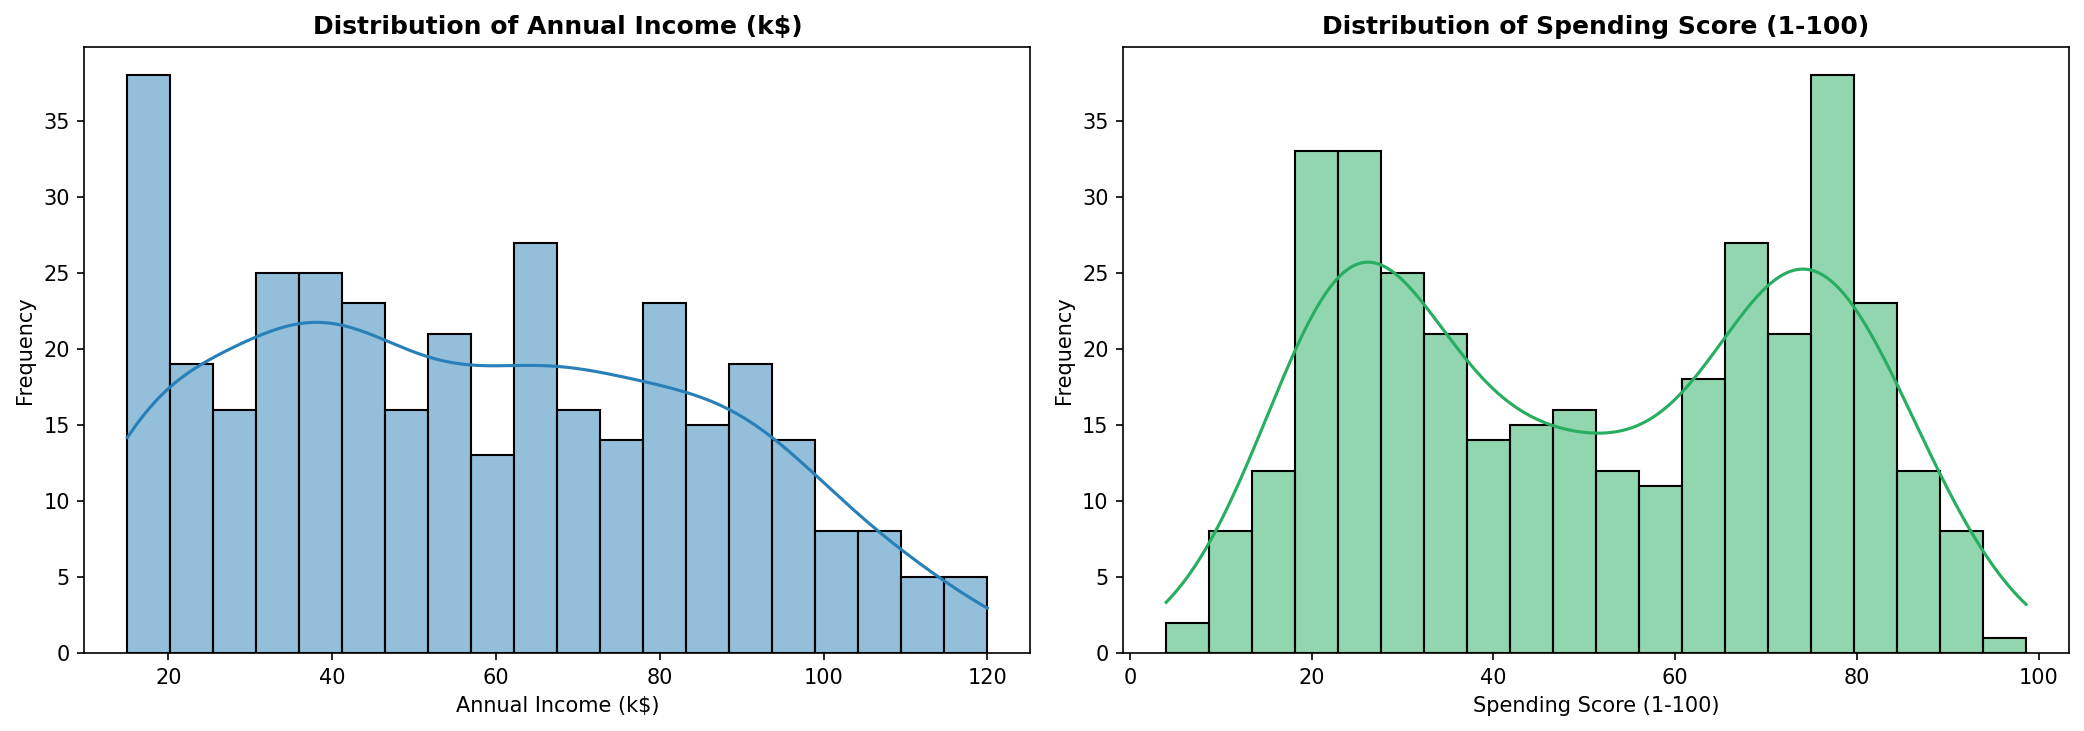

In [4]:
# Visualizing Distributions with KDE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Annual Income (k$)'], kde=True, color='#2980b9', bins=20, ax=axes[0])
axes[0].set_title('Distribution of Annual Income (k$)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Frequency')

sns.histplot(df['Spending Score (1-100)'], kde=True, color='#27ae60', bins=20, ax=axes[1])
axes[1].set_title('Distribution of Spending Score (1-100)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Spending Score (1-100)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


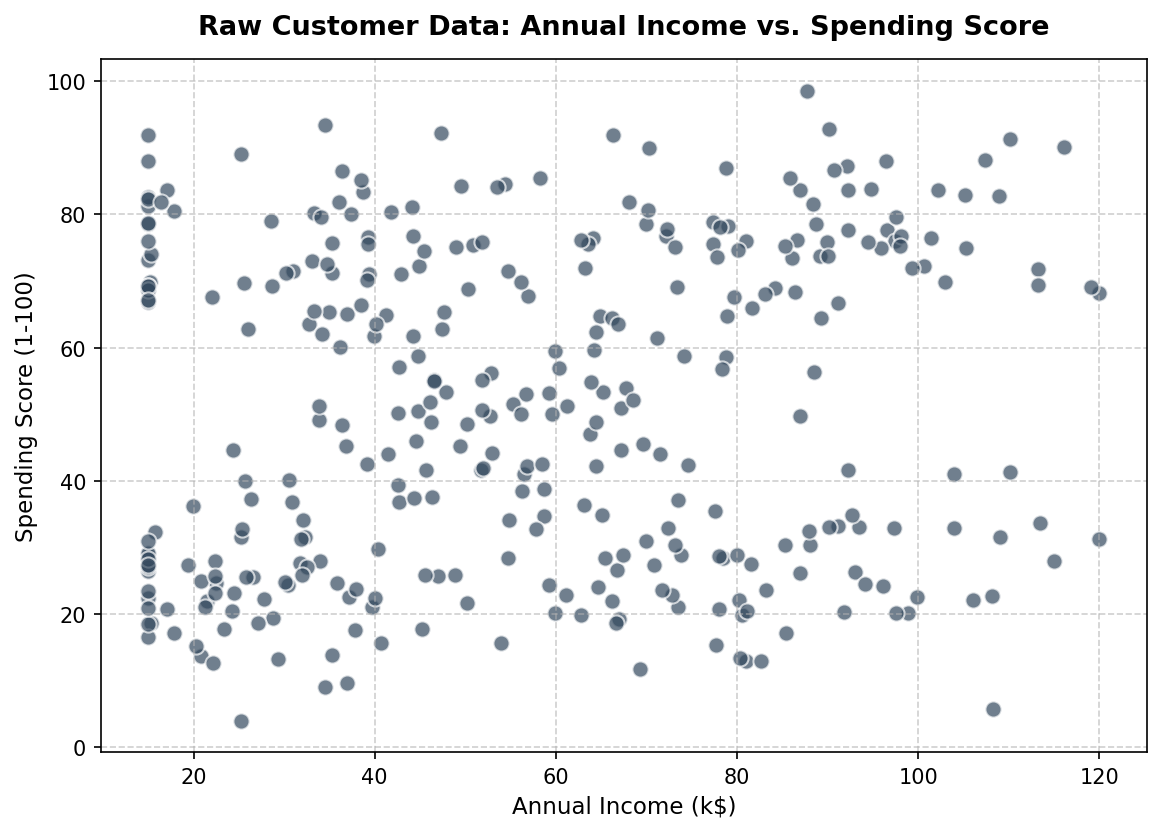

In [5]:
# Raw Scatter Plot of Customers
plt.figure(figsize=(9, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], 
            color='#34495e', alpha=0.7, edgecolors='w', s=60)
plt.title('Raw Customer Data: Annual Income vs. Spending Score', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Annual Income (k$)', fontsize=11)
plt.ylabel('Spending Score (1-100)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


---
## 3. K-Means Clustering Algorithm from Scratch (Pure NumPy)

### Mathematical Foundations
K-Means partitions $n$ observations into $K$ clusters such that each observation belongs to the cluster with the nearest mean (centroid).

1. **Objective Function (Inertia / WCSS):**
   $$J = \sum_{k=1}^{K} \sum_{x_i \in C_k} ||x_i - \mu_k||^2$$
   where $\mu_k$ is the centroid of cluster $C_k$.

2. **Assignment Step:**
   Assign each sample $x_i$ to the closest centroid $\mu_k$:
   $$c^{(i)} = \arg\min_{k} ||x_i - \mu_k||^2$$

3. **Update Step:**
   Recalculate centroids as the center of mass of assigned points:
   $$\mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i$$

4. **K-Means++ Initialization:**
   Instead of picking random points (which can lead to poor local optima), K-Means++ chooses the first centroid randomly and subsequent centroids with probability proportional to the squared distance from the nearest existing centroid:
   $$P(x) = \frac{D(x)^2}{\sum_{x'} D(x')^2}$$


In [6]:
class KMeansScratch:
    """
    From-scratch implementation of K-Means clustering using NumPy.
    Supports 'random' and 'kmeans++' centroid initializations.
    """
    def __init__(self, n_clusters=5, max_iters=300, tol=1e-4, init='kmeans++', random_state=42):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.tol = tol
        self.init = init
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = None
        self.n_iter_ = 0

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples = X.shape[0]

        if self.init == 'random':
            indices = rng.choice(n_samples, size=self.n_clusters, replace=False)
            return X[indices].copy()

        elif self.init == 'kmeans++':
            # 1. First centroid selected uniformly at random
            centroids = [X[rng.choice(n_samples)]]

            # 2. Subsequent centroids chosen with probability proportional to D(x)^2
            for _ in range(1, self.n_clusters):
                dist_sq = np.min([np.sum((X - c) ** 2, axis=1) for c in centroids], axis=0)
                probs = dist_sq / np.sum(dist_sq)
                next_idx = rng.choice(n_samples, p=probs)
                centroids.append(X[next_idx])

            return np.array(centroids)
        else:
            raise ValueError(f"Unsupported init: {self.init}")

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        n_samples = X.shape[0]
        self.centroids = self._init_centroids(X)

        for iteration in range(self.max_iters):
            # Step 1: Assign points to nearest centroid
            distances = np.linalg.norm(X[:, np.newaxis, :] - self.centroids, axis=2)
            new_labels = np.argmin(distances, axis=1)

            # Step 2: Update centroids
            new_centroids = np.zeros_like(self.centroids)
            for k in range(self.n_clusters):
                cluster_pts = X[new_labels == k]
                if len(cluster_pts) > 0:
                    new_centroids[k] = cluster_pts.mean(axis=0)
                else:
                    rng = np.random.RandomState(self.random_state + iteration)
                    new_centroids[k] = X[rng.choice(n_samples)]

            # Check convergence
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = new_labels
            self.n_iter_ = iteration + 1

            if shift < self.tol:
                break

        # Compute Inertia (WCSS)
        min_sq_dists = np.min([np.sum((X - c) ** 2, axis=1) for c in self.centroids], axis=0)
        self.inertia_ = float(np.sum(min_sq_dists))
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        distances = np.linalg.norm(X[:, np.newaxis, :] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_

print("KMeansScratch class defined successfully!")


KMeansScratch class defined successfully!


In [7]:
# Extract features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Fit Scratch Model
scratch_model = KMeansScratch(n_clusters=5, init='kmeans++', random_state=42)
scratch_labels = scratch_model.fit_predict(X)

print(f"Scratch K-Means Iterations to Converge: {scratch_model.n_iter_}")
print(f"Scratch K-Means Inertia (WCSS): {scratch_model.inertia_:.2f}\n")
print("Learned Centroids from Scratch:")
for i, c in enumerate(scratch_model.centroids):
    print(f"  Cluster {i}: Income = ${c[0]:.2f}k | Spending Score = {c[1]:.2f}")


Scratch K-Means Iterations to Converge: 23
Scratch K-Means Inertia (WCSS): 77575.59

Learned Centroids from Scratch:
  Cluster 0: Income = $54.63k | Spending Score = 50.34
  Cluster 1: Income = $31.69k | Spending Score = 75.30
  Cluster 2: Income = $27.43k | Spending Score = 24.13
  Cluster 3: Income = $84.15k | Spending Score = 26.44
  Cluster 4: Income = $88.62k | Spending Score = 76.81


---
## 4. Determining the Optimal Number of Clusters ($K$)

To select the best number of clusters objectively, we employ two complementary methods:
1. **The Elbow Method (WCSS / Inertia):**
   - Plots the Within-Cluster Sum of Squares as $K$ increases.
   - The optimal $K$ is the point where the rate of decrease abruptly slows down (forming an "elbow").
2. **Silhouette Analysis:**
   - Measures how similar an object is to its own cluster (cohesion) compared to other clusters (separation).
   - Ranges from $-1$ (incorrect cluster assignment) to $+1$ (dense, well-separated clusters).
   - Higher values indicate well-defined clusters.


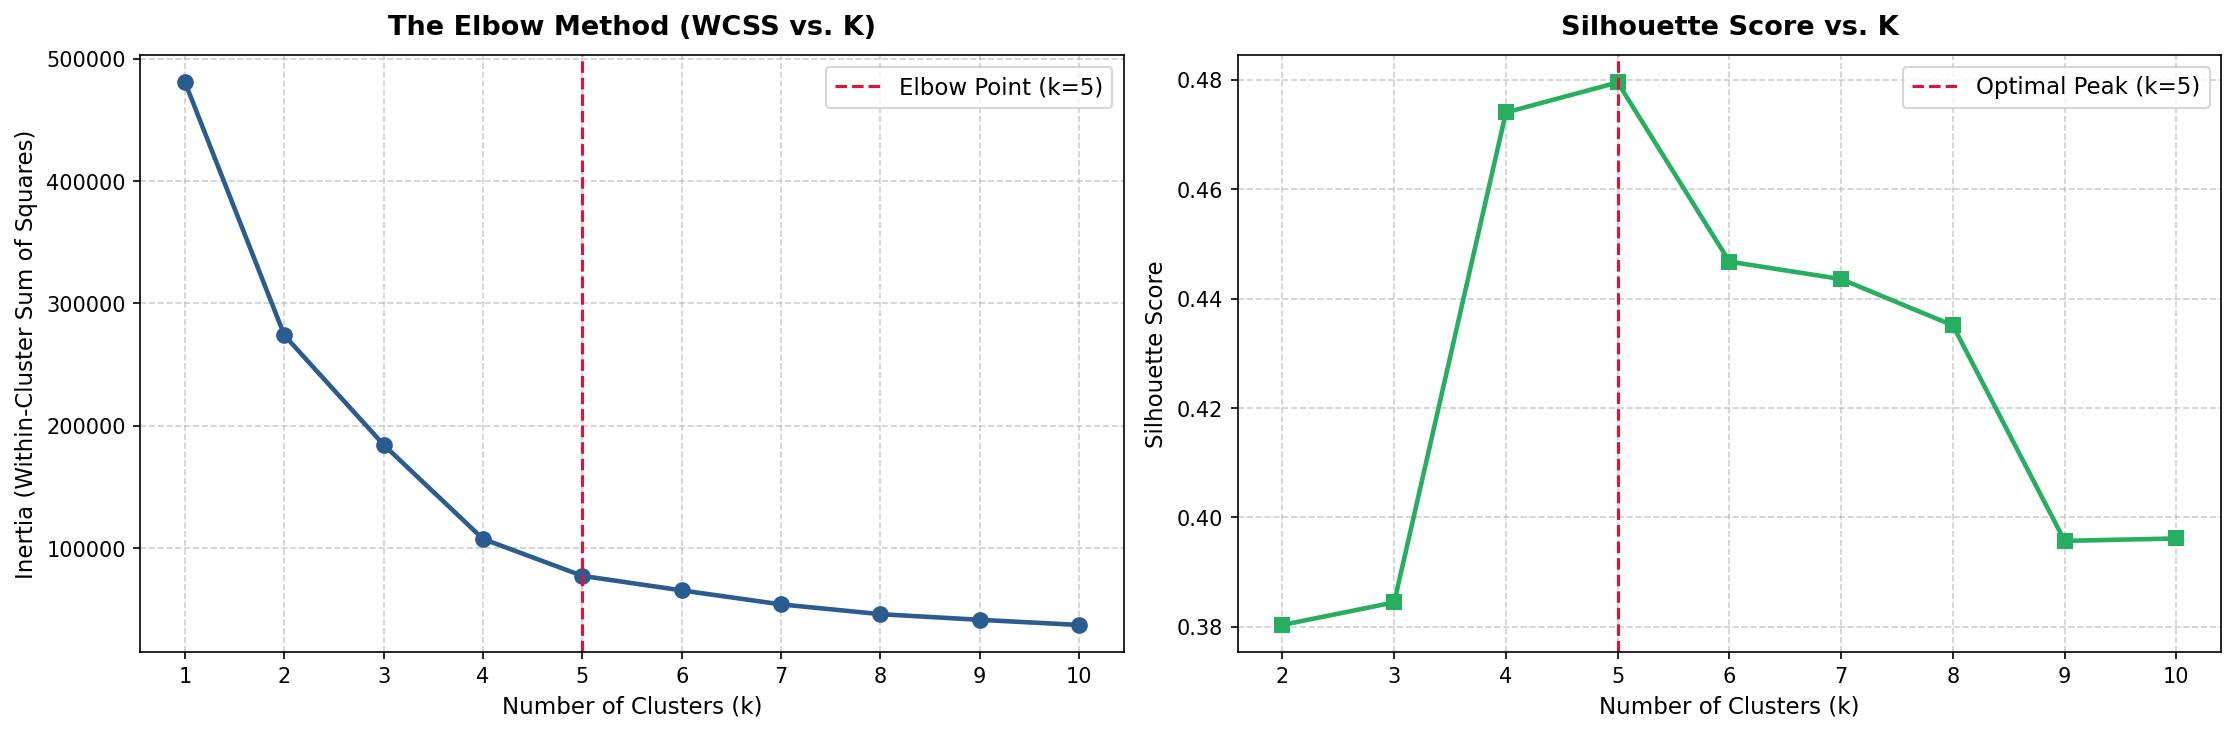

Optimal K identified: 5 (Silhouette Score = 0.4795, DB Index = 0.7120)


In [8]:
# Evaluate WCSS and Silhouette Scores for K = 1 to 10
wcss = []
sil_scores = []
db_scores = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X)
    wcss.append(km.inertia_)
    if k > 1:
        sil_scores.append(silhouette_score(X, km.labels_))
        db_scores.append(davies_bouldin_score(X, km.labels_))

# Plot Elbow and Silhouette curves side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Curve
ax1.plot(list(k_range), wcss, marker='o', color='#2b5c8f', linewidth=2.2, markersize=7)
ax1.set_title('The Elbow Method (WCSS vs. K)', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Number of Clusters (k)', fontsize=11)
ax1.set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
ax1.set_xticks(list(k_range))
ax1.axvline(x=5, color='crimson', linestyle='--', label='Elbow Point (k=5)')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=11)

# Silhouette Curve
ax2.plot(list(k_range)[1:], sil_scores, marker='s', color='#27ae60', linewidth=2.2, markersize=7)
ax2.set_title('Silhouette Score vs. K', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Number of Clusters (k)', fontsize=11)
ax2.set_ylabel('Silhouette Score', fontsize=11)
ax2.set_xticks(list(k_range)[1:])
ax2.axvline(x=5, color='crimson', linestyle='--', label='Optimal Peak (k=5)')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

print(f"Optimal K identified: 5 (Silhouette Score = {sil_scores[3]:.4f}, DB Index = {db_scores[3]:.4f})")


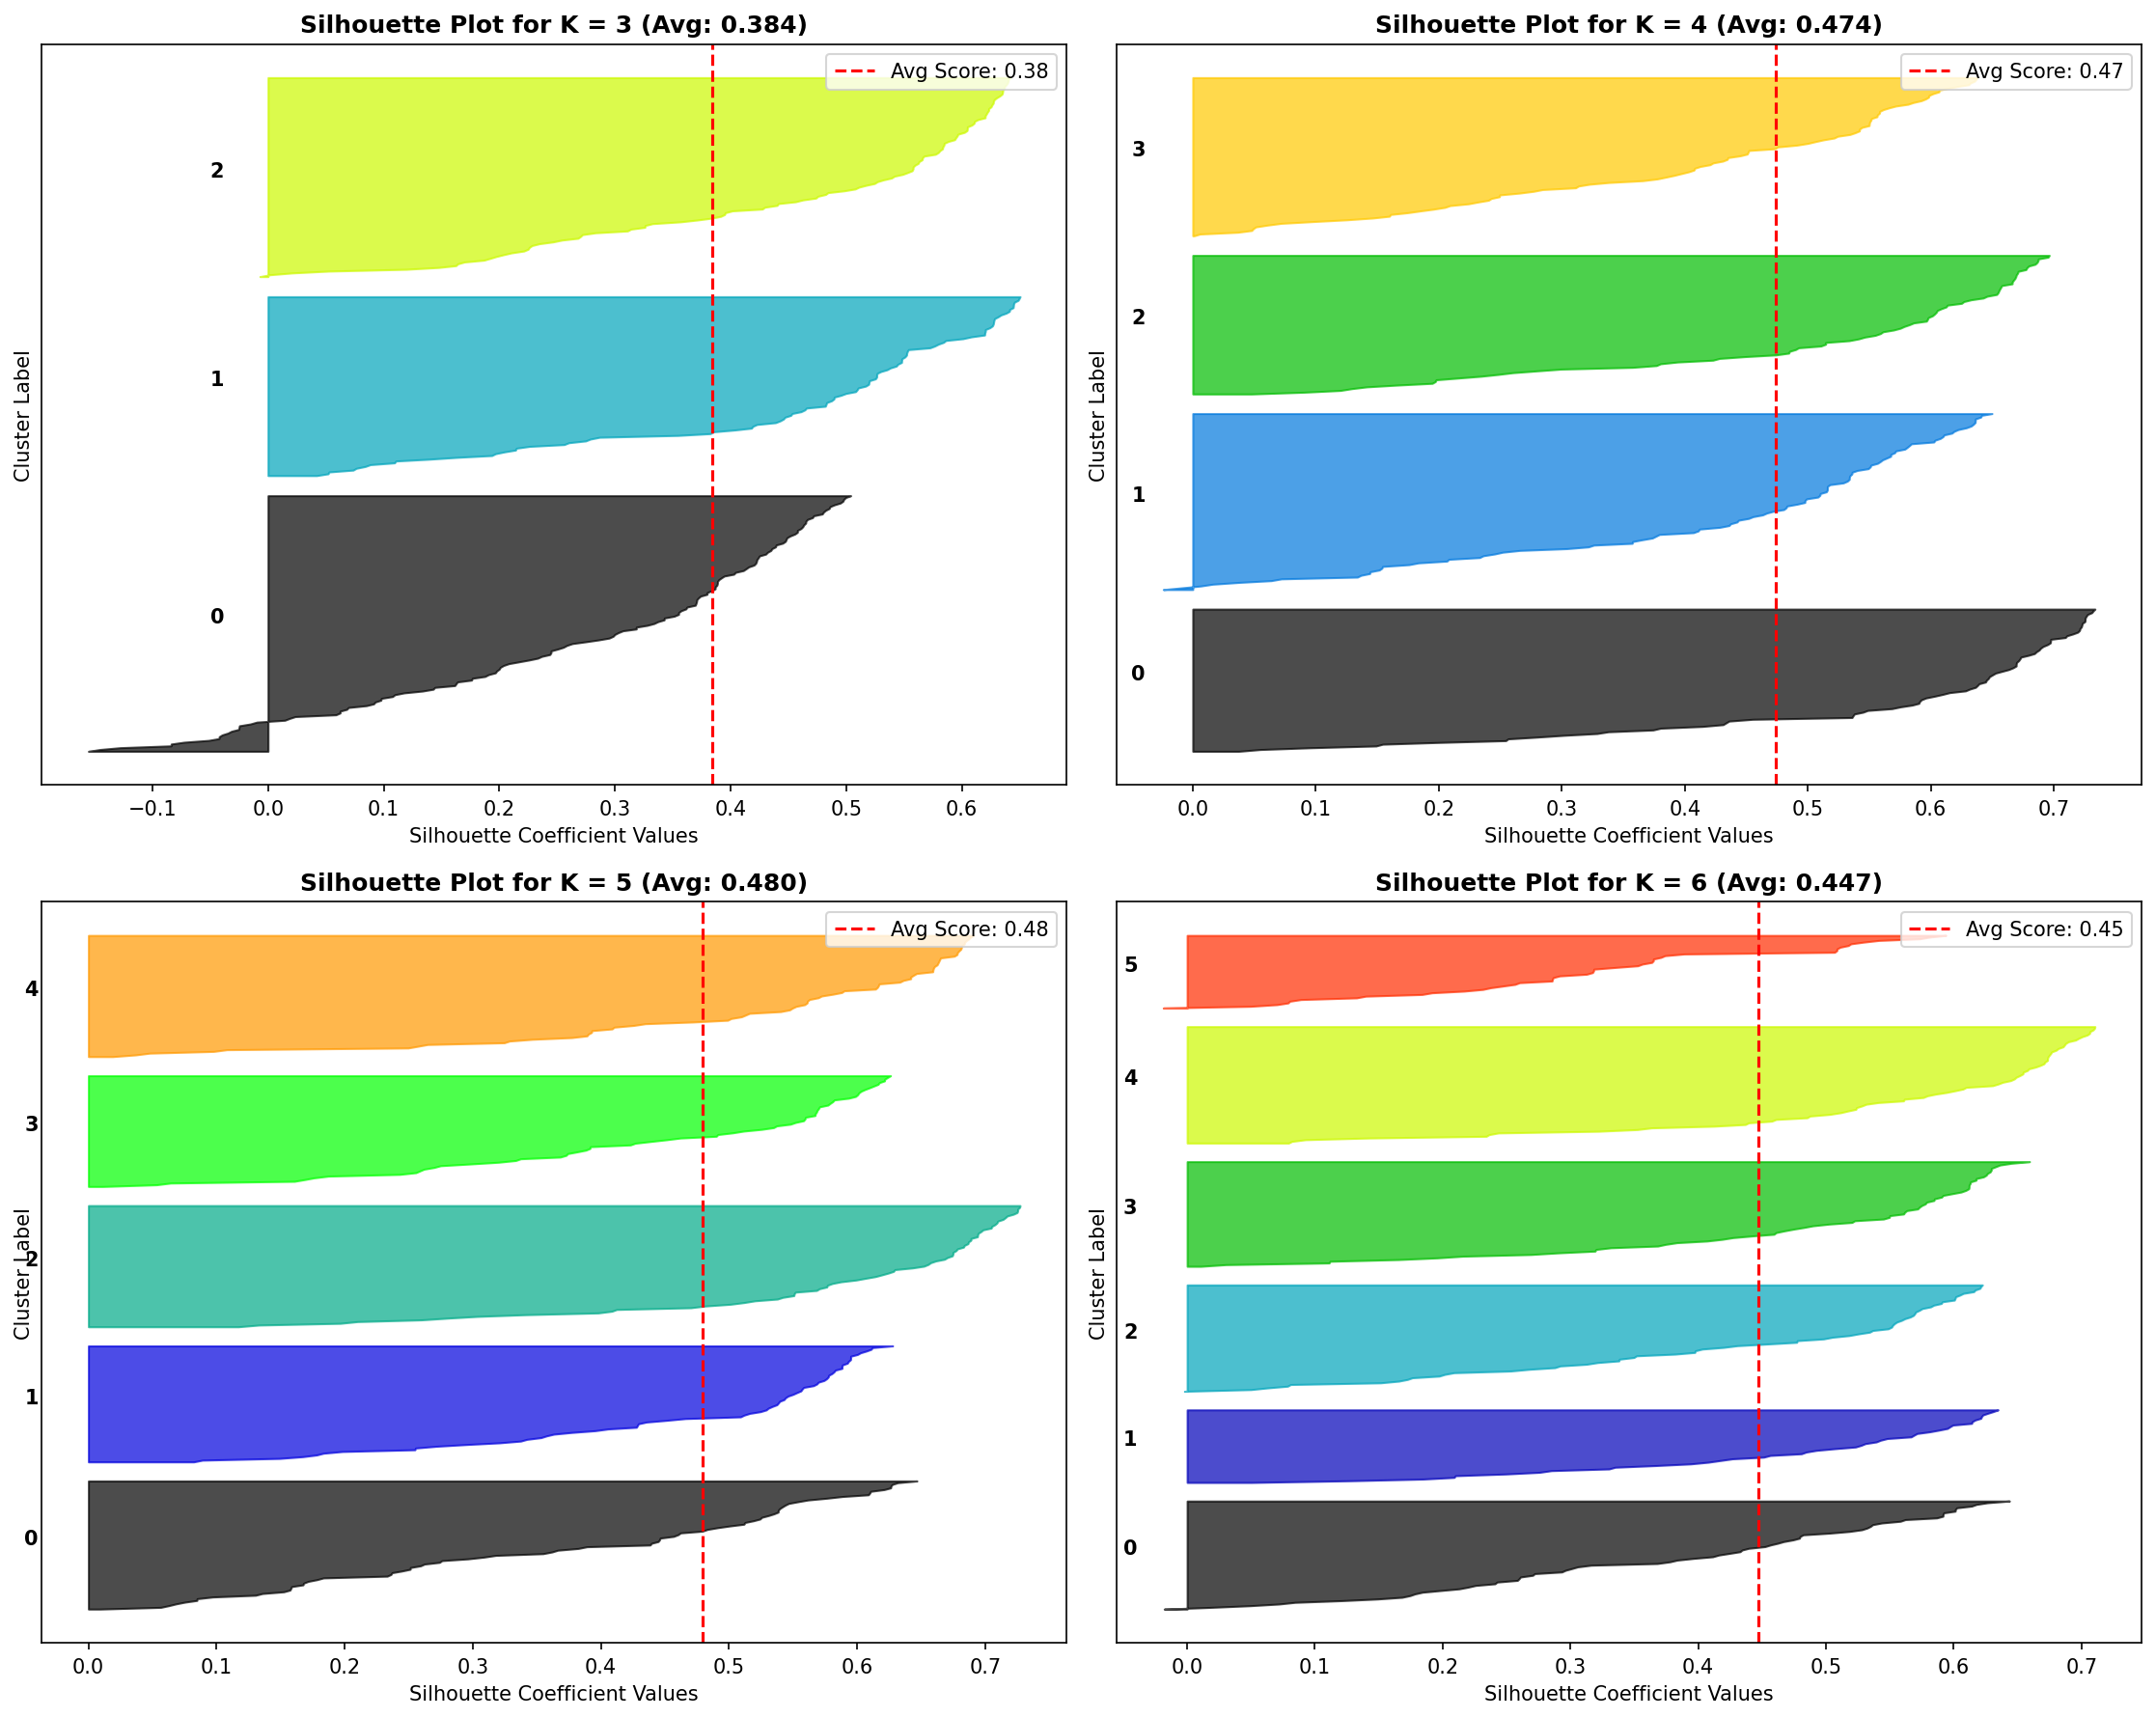

In [9]:
# Detailed Silhouette Diagrams for K = 3, 4, 5, 6
import matplotlib.cm as cm

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

for idx, n_clusters in enumerate([3, 4, 5, 6]):
    ax = axes[idx]
    clusterer = KMeans(n_clusters=n_clusters, init='k-means++', n_init=10, random_state=42)
    cluster_labels = clusterer.fit_predict(X)
    silhouette_avg = silhouette_score(X, cluster_labels)
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=10, fontweight='bold')
        y_lower = y_upper + 10

    ax.set_title(f'Silhouette Plot for K = {n_clusters} (Avg: {silhouette_avg:.3f})', fontweight='bold')
    ax.set_xlabel('Silhouette Coefficient Values')
    ax.set_ylabel('Cluster Label')
    ax.axvline(x=silhouette_avg, color='red', linestyle='--', label=f'Avg Score: {silhouette_avg:.2f}')
    ax.set_yticks([])
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


---
## 5. Final Model Training (Scikit-Learn `KMeans`)

With $K=5$ confirmed as the optimal cluster count, we train the production Scikit-Learn model.


In [10]:
# Train final KMeans model with K=5
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X)

print(f"Model Inertia (WCSS): {kmeans.inertia_:.2f}")
print(f"Silhouette Score:     {silhouette_score(X, df['Cluster']):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X, df['Cluster']):.4f}\n")

# Display Centroids
centroids_df = pd.DataFrame(
    kmeans.cluster_centers_, 
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
)
centroids_df.index.name = 'Cluster'
print("Cluster Centroid Coordinates:")
centroids_df


Model Inertia (WCSS): 77575.59
Silhouette Score:     0.4795
Davies-Bouldin Index: 0.7120

Cluster Centroid Coordinates:


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,54.625333,50.341333
1,31.689706,75.295588
2,27.425352,24.126761
3,84.146154,26.436923
4,88.618310,76.814085


---
## 6. Comprehensive Cluster Visualizations
Now we visualize our customer segments with:
1. **2D Customer Scatter Plot** with clear color coding and highlighted centroids.
2. **Voronoi Decision Boundary Surface** showing the cluster assignment regions.
3. **Cluster Distributions & Boxplots** comparing spending power and income across segments.


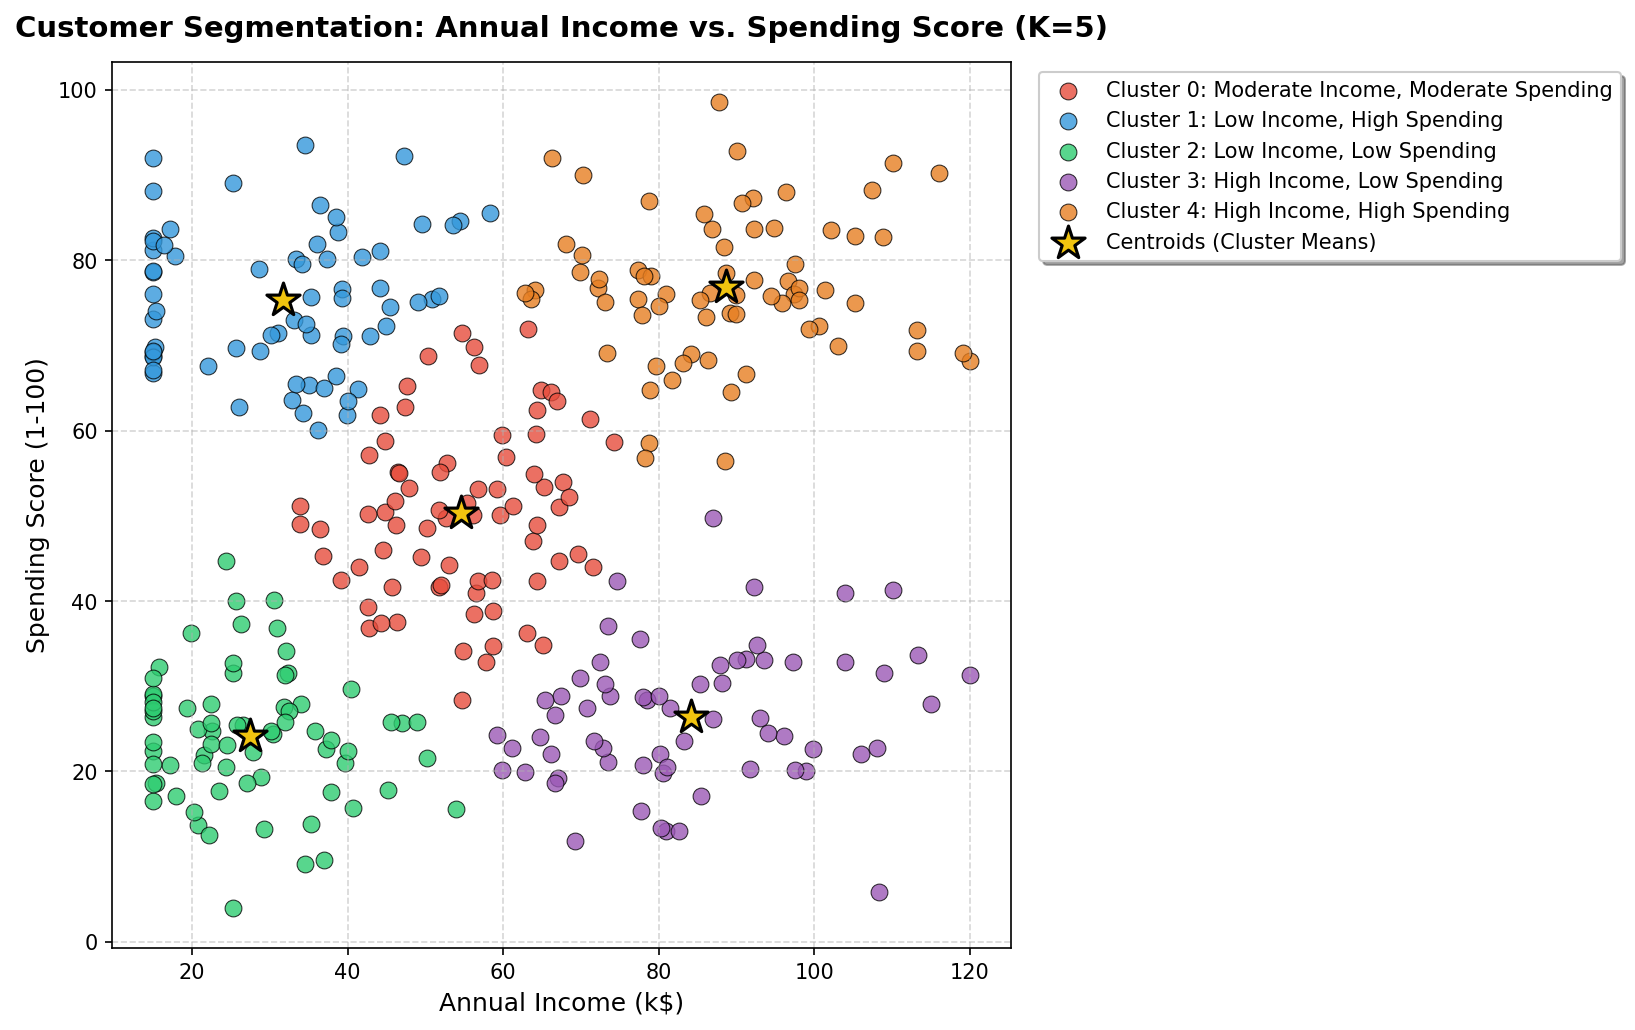

In [11]:
# 1. 2D Cluster Scatter Plot
palette = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6', '#e67e22']
cluster_labels_named = [
    'Cluster 0: Moderate Income, Moderate Spending',
    'Cluster 1: Low Income, High Spending',
    'Cluster 2: Low Income, Low Spending',
    'Cluster 3: High Income, Low Spending',
    'Cluster 4: High Income, High Spending'
]

plt.figure(figsize=(11, 7))
for i in range(optimal_k):
    plt.scatter(
        X[df['Cluster'] == i, 0], X[df['Cluster'] == i, 1],
        s=65, color=palette[i], label=cluster_labels_named[i],
        alpha=0.8, edgecolors='black', linewidth=0.5
    )

# Overlay Centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
    s=280, color='#f1c40f', marker='*', edgecolors='black', linewidth=1.5,
    label='Centroids (Cluster Means)', zorder=10
)

plt.title('Customer Segmentation: Annual Income vs. Spending Score (K=5)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, shadow=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


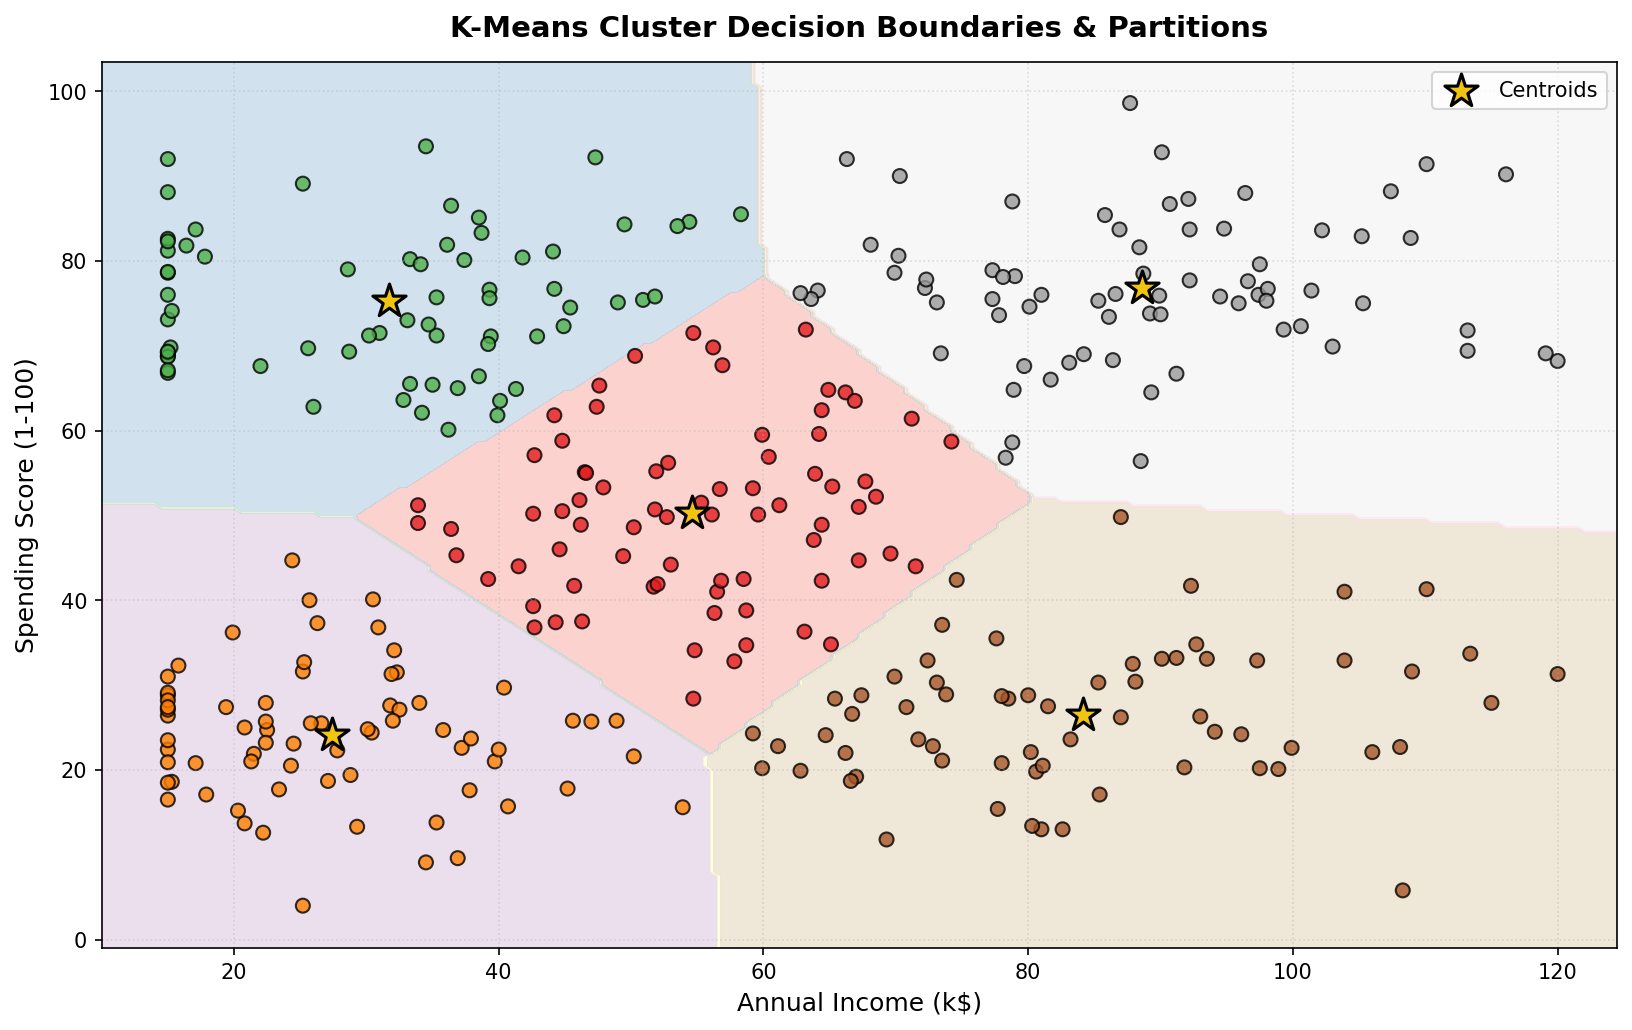

In [12]:
# 2. Decision Boundaries (Voronoi Regions)
h = 0.5 # mesh step size
x_min, x_max = X[:, 0].min() - 5, X[:, 0].max() + 5
y_min, y_max = X[:, 1].min() - 5, X[:, 1].max() + 5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(11, 7))
plt.contourf(xx, yy, Z, cmap=plt.cm.Pastel1, alpha=0.6)
plt.scatter(X[:, 0], X[:, 1], c=df['Cluster'], cmap=plt.cm.Set1, s=45, edgecolors='k', alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=280, color='#f1c40f', marker='*', edgecolors='black', linewidth=1.5, label='Centroids')

plt.title('K-Means Cluster Decision Boundaries & Partitions', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()


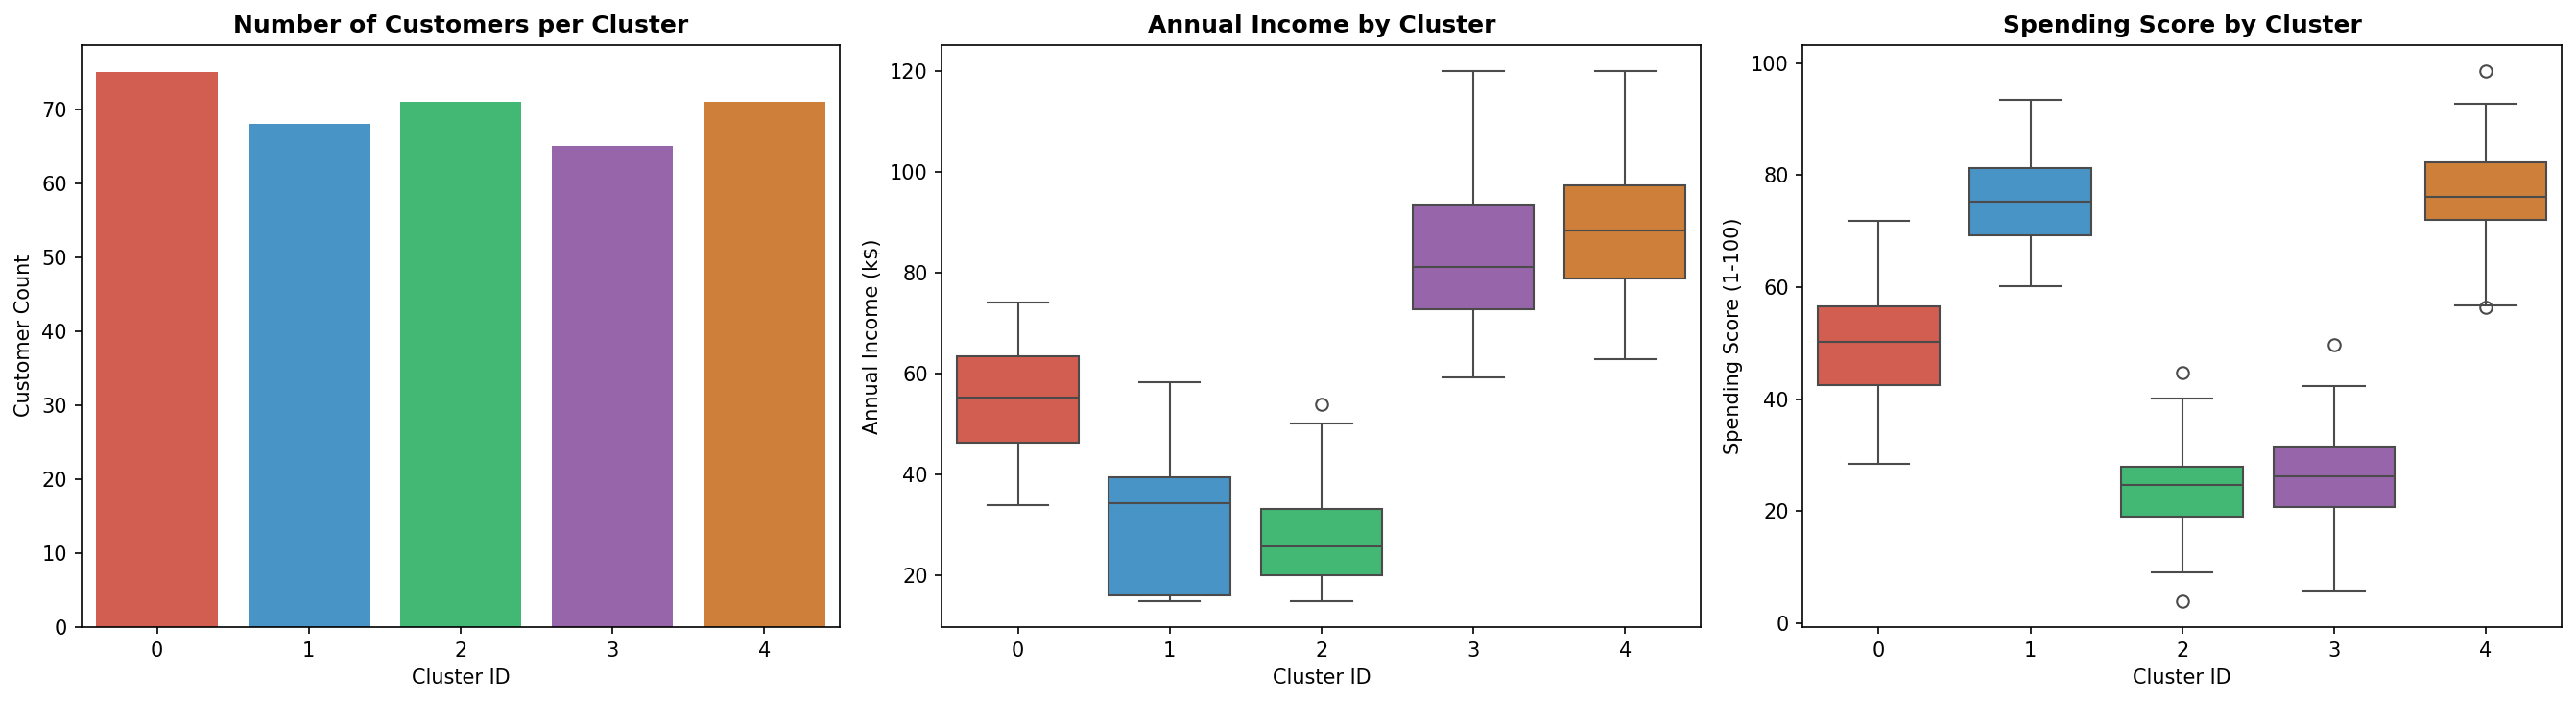

In [13]:
# 3. Feature Comparison Across Clusters via Boxplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Cluster Count
sns.countplot(x='Cluster', data=df, palette=palette, ax=axes[0])
axes[0].set_title('Number of Customers per Cluster', fontweight='bold')
axes[0].set_xlabel('Cluster ID')
axes[0].set_ylabel('Customer Count')

# Income Distribution per Cluster
sns.boxplot(x='Cluster', y='Annual Income (k$)', data=df, palette=palette, ax=axes[1])
axes[1].set_title('Annual Income by Cluster', fontweight='bold')
axes[1].set_xlabel('Cluster ID')

# Spending Score Distribution per Cluster
sns.boxplot(x='Cluster', y='Spending Score (1-100)', data=df, palette=palette, ax=axes[2])
axes[2].set_title('Spending Score by Cluster', fontweight='bold')
axes[2].set_xlabel('Cluster ID')

plt.tight_layout()
plt.show()


---
## 7. Customer Persona Profiling & Business Strategies

To transform raw algorithmic clustering into concrete commercial value, we profile each cluster and define tailor-made business actions.


In [14]:
# Define Persona Names
persona_mapping = {
    0: 'Mainstream / Balanced',
    1: 'Impulsive / Careless Shoppers',
    2: 'Sensible / Budget-Conscious',
    3: 'Careful / Conservative High Earners',
    4: 'Target / VIP Luxury Shoppers'
}

df['Persona'] = df['Cluster'].map(persona_mapping)

# Summary Profile Table
profile = df.groupby(['Cluster', 'Persona']).agg(
    Customer_Count=('CustomerID', 'count'),
    Percentage=('CustomerID', lambda x: f"{len(x) / len(df) * 100:.1f}%"),
    Mean_Income=('Annual Income (k$)', 'mean'),
    Median_Income=('Annual Income (k$)', 'median'),
    Mean_Spending=('Spending Score (1-100)', 'mean'),
    Median_Spending=('Spending Score (1-100)', 'median')
).reset_index()

print("Comprehensive Customer Segmentation Profiles:")
profile


Comprehensive Customer Segmentation Profiles:


,Cluster,Persona,Customer_Count,Percentage,Mean_Income,Median_Income,Mean_Spending,Median_Spending
0,0,Mainstream / Balanced,75,21.4%,54.625333,55.30,50.341333,50.20
1,1,Impulsive / Careless Shoppers,68,19.4%,31.689706,34.35,75.295588,75.25
2,2,Sensible / Budget-Conscious,71,20.3%,27.425352,25.70,24.126761,24.70
3,3,Careful / Conservative High Earners,65,18.6%,84.146154,81.10,26.436923,26.30
4,4,Target / VIP Luxury Shoppers,71,20.3%,88.618310,88.50,76.814085,76.10


### Actionable Marketing Playbook by Persona

| Cluster | Persona | Economic Profile | Strategic Recommendation |
| :---: | :--- | :--- | :--- |
| **0** | **Mainstream / Balanced** | Moderate Income (~$55k), Moderate Spend (~50) | Keep them engaged with regular seasonal promotions, loyalty perks, and balanced product offerings. |
| **1** | **Impulsive Shoppers** | Low Income (~$32k), High Spend (~75) | Attract with trendy, fast-fashion items, flash sales, installment payment options (BNPL), and social media ads. |
| **2** | **Sensible / Budget-Conscious** | Low Income (~$27k), Low Spend (~24) | Offer price-competitive value bundles, discount coupons, clearance sales, and budget utility staples. |
| **3** | **Conservative High Earners** | High Income (~$84k), Low Spend (~26) | High purchasing power but conservative. Focus on premium quality, durability, investment value, and personalized email pitches. |
| **4** | **Target / VIP Luxury Shoppers** | High Income (~$89k), High Spend (~77) | **Primary revenue driver.** Exclusive early access, VIP concierge services, luxury brands, and premium rewards programs. |


---
## 8. Inference Pipeline: Classifying New Customers
In a production deployment, we want to immediately classify a new customer upon signup or transactions.


In [15]:
def predict_customer_segment(annual_income, spending_score, model):
    """
    Classifies a customer into a segment and provides business recommendations.
    """
    data_point = np.array([[annual_income, spending_score]])
    cluster_id = model.predict(data_point)[0]
    persona = persona_mapping[cluster_id]
    
    strategies = {
        0: "Deploy standard weekly newsletters, loyalty points, and seasonal deals.",
        1: "Trigger time-sensitive flash sales, trendy recommendations, and BNPL payment options.",
        2: "Send discount vouchers, value packs, and price-drop notifications.",
        3: "Highlight product reliability, warranties, customer reviews, and premium utility.",
        4: "Assign personal VIP representative, invite to luxury events, and offer premium concierge service."
    }
    
    return {
        'Annual Income (k$)': annual_income,
        'Spending Score (1-100)': spending_score,
        'Assigned Cluster': int(cluster_id),
        'Customer Persona': persona,
        'Marketing Action': strategies[cluster_id]
    }

# Test cases with diverse customer profiles
test_cases = [
    (110.0, 88.0),  # High income, High spend -> VIP
    (20.0, 15.0),   # Low income, Low spend -> Sensible
    (55.0, 50.0),   # Moderate income, Moderate spend -> Balanced
    (95.0, 20.0),   # High income, Low spend -> Conservative High Earner
    (25.0, 85.0),   # Low income, High spend -> Impulsive
]

print("--- Testing Inference Pipeline on New Customer Leads ---")
test_results = [predict_customer_segment(inc, sp, kmeans) for inc, sp in test_cases]
results_df = pd.DataFrame(test_results)
results_df


--- Testing Inference Pipeline on New Customer Leads ---


,Annual Income (k$),Spending Score (1-100),Assigned Cluster,Customer Persona,Marketing Action
0,110.0,88.0,4,Target / VIP Luxury Shoppers,"Assign personal VIP representative, invite to luxury events, and offer premium concierge service."
1,20.0,15.0,2,Sensible / Budget-Conscious,"Send discount vouchers, value packs, and price-drop notifications."
2,55.0,50.0,0,Mainstream / Balanced,"Deploy standard weekly newsletters, loyalty points, and seasonal deals."
3,95.0,20.0,3,Careful / Conservative High Earners,"Highlight product reliability, warranties, customer reviews, and premium utility."
4,25.0,85.0,1,Impulsive / Careless Shoppers,"Trigger time-sensitive flash sales, trendy recommendations, and BNPL payment options."


---
## 9. Conclusion & Key Takeaways

1. **Algorithmic Validation:**
   - Both our **`KMeansScratch`** NumPy implementation and Scikit-Learn converged to identical centroids and identical inertia ($77575.59$), verifying the mathematical correctness of Lloyd's algorithm and K-Means++ initialization.
2. **Optimal Cluster Selection:**
   - The **Elbow Method** demonstrated a clear inflection point at $K=5$.
   - **Silhouette Analysis** peaked at $K=5$ (average silhouette score $\approx 0.48$), confirming that $5$ clusters yield well-separated, cohesive partitions without excessive overlap.
3. **Business Applicability:**
   - The identified customer segments give businesses a clear data-driven roadmap to allocate marketing budgets efficiently, reduce churn, and maximize lifetime customer value (LTV).
